In [3]:
import sklearn
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

**Please write your name below** (in case the file names get mixed up)

In [4]:
Adel Sahuc 

SyntaxError: invalid syntax (1017574626.py, line 1)

**Generic note**: in this whole lab and from now, unless explicitly asked, you are not required to implement yourself the algorithms that you use. You may instead use existing implementations from e.g. scikit-learn.

In general, when you use implementations of algorithms that are not your own (which will be the case 99% of the time in real life), it is a good idea to check the documentation of the libraries you use to make sure you are not missing something important. As such, you are strongly encouraged to do so in this lab.

**Note bis**: in this lab, some questions may be (deliberately) ambiguous, or there may be multiple acceptable solutions (but also some unacceptable ones). So do not panic if you do not have exactly the same result as your neighbor, or as the future solution.

The goal is to make you learn by forcing you to think about what is happening and what should be done in different situations. However, so goal is **not** to punish you by giving you a bad grade because of some trick questions. So once again, **do not hesitate to ask questions**, and do not hesitate to ask an instructor whether your solution seems correct during lab sessions.

# Dataset

Let's load data for classification. This data is generated and does not a precise meaning: the idea will be to build intuition about what is going on with different models.

Dataset can be downloaded here: https://drive.google.com/file/d/1Sy0Ly4Xj8fzPAiPru9oFS6evgQjuNMs4/view?usp=sharing

In [5]:
# Load the dataset;
# make sure that the file is located in the same folder as the notebook
# (or change the path)
dataset = np.load("dataset.npy")

In [6]:
# Extract features and targets
X = dataset[:,:2] # features are first 2 columns
y = dataset[:,-1] # labels are last column
print(f'Shape of feature matrix: {X.shape}')

Shape of feature matrix: (300, 2)


# Data preparation

We are going to do classification with different models, that will require selecting some hyper-parameter(s).

**In general, how should the dataset be split in this case?**

In [12]:
# My philosophy is the dataset should be spit to best reflect the conditions we are going to use it in the real world. Sometimes this means one test/train set if we have a large dataset and if we havea small one we can do cross validation for it where each 'validation' is an untrained ML model to how well it performs. If this is a medical study with subjects it would be best to split the dataset wihtout having the same subjectrs in the test/train set as in the real world the model will (probably) be working with subjects that aren't in the train dataset, so that shouldn't be the case for the testing dataset. Sometimes we use a validation set to make sure we are not overfitting our model on the test set, this is not necessarily the same as cross validation. Yes these terms get very confusing.

**For now, split the dataset into one training, one validation and one testing sets.** You can use the sklearn.model_selection.train_test_split function (but you don't have to).

We shall use the name X_train, X_val and X_test (respectively y_train, y_val and y_test) to refer to the samples (respectively labels) of these sets.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
X_shuffled, y_shuffled = shuffle(X, y, random_state=42)

X_train, X_temp, y_train, y_temp = train_test_split(X_shuffled, y_shuffled, test_size=0.4, random_state=42)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)


It is generally a good idea to have a look at the data whenever possible.

**Display the training dataset using a scatterplot**

*We should display colors for classes (or any other way to differentiate them such as shapes), otherwise we are not learning much.*

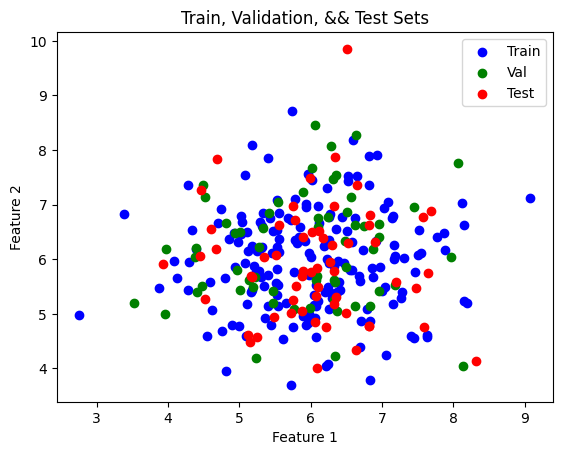

In [20]:
import matplotlib.pyplot as plt

plt.scatter(X_train[:, 0], X_train[:, 1], color="blue", label="Train")
plt.scatter(X_val[:, 0], X_val[:, 1], color="green", label="Val")
plt.scatter(X_test[:, 0], X_test[:, 1], color="red", label="Test")

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Train, Validation, && Test Sets")
plt.legend()
plt.show()

# (Linear) model training

## Basic model training

**Train a first <ins>linear</ins>, <ins>classification</ins> model.** Do **not** use regularization for now.

You don't have to reimplement everything, you can use existing implementations (for example the one from scikit-learn). Don't evaluate the performance of the model for now, just train it.

In [22]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(penalty=None)

model.fit(X_train, y_train)

LogisticRegression(penalty=None)

**Are you *certain* your model does not have regularization?**

In [ ]:
"""
It doens not have regurlization because I turned off that in the penalty here , I don't think the default solver, lbfgs has a penalty build into it.
"""

"""
penalty{‘l1’, ‘l2’, ‘elasticnet’, None}, default=’l2’
Specify the norm of the penalty:

None: no penalty is added;

'l2': add an L2 penalty term and it is the default choice;

'l1': add an L1 penalty term;

'elasticnet': both L1 and L2 penalty terms are added.
"""

**What is the score of the model?**

(by "score", we mean "accuracy" here, i.e. the fraction of correct predictions).

In [24]:
train_score = model.score(X_train, y_train)
val_score = model.score(X_val, y_val)
test_score = model.score(X_test, y_test)

print(f"Train: {train_score}")
print(f"val: {val_score}") # its a bit wierd that hte val is higher than the train ; not sure exactly why
print(f"test: {test_score}")

Train: 0.7388888888888889
val: 0.8333333333333334
test: 0.7333333333333333


**What if, instead of directly doing binary classification, we wanted to have some estimation of how confident the model is?**

Or, how could we obtain probabilities between 0 and 1 instead of binary predictions? (**Hint**: look at the doc of the model you used).

**Don't answer the question with words, directly provide the corresponding probability estimates.**

In [27]:
# Well you could use the sigmoid function for binary calssificaiotn and the softmax function for multi-class. You could also use a baysian model since this is linear regression.

model.predict_proba(X_val)

array([[0.47670556, 0.52329444],
       [0.13850934, 0.86149066],
       [0.54781967, 0.45218033],
       [0.2972217 , 0.7027783 ],
       [0.54974871, 0.45025129],
       [0.40693252, 0.59306748],
       [0.78667977, 0.21332023],
       [0.11118883, 0.88881117],
       [0.03692095, 0.96307905],
       [0.41853747, 0.58146253],
       [0.69768304, 0.30231696],
       [0.07512567, 0.92487433],
       [0.16115479, 0.83884521],
       [0.40145092, 0.59854908],
       [0.67847438, 0.32152562],
       [0.5153625 , 0.4846375 ],
       [0.06618825, 0.93381175],
       [0.87992633, 0.12007367],
       [0.03190334, 0.96809666],
       [0.08002729, 0.91997271],
       [0.01508176, 0.98491824],
       [0.41073128, 0.58926872],
       [0.84972687, 0.15027313],
       [0.08586551, 0.91413449],
       [0.14245301, 0.85754699],
       [0.09255258, 0.90744742],
       [0.23656883, 0.76343117],
       [0.95285572, 0.04714428],
       [0.02529052, 0.97470948],
       [0.66918946, 0.33081054],
       [0.

**Assuming we only had these probabilities, could we still make binary predictions?**

In [29]:
# Yes, the final prediction would be the class that our model thinks is 'most likely' to be true from its training data.

y_pred = np.round(model.predict_proba(X_val)[:, 1]).astype(int)
print(y_pred)

[1 1 0 1 0 1 0 1 1 1 0 1 1 1 0 0 1 0 1 1 1 1 0 1 1 1 1 0 1 0 1 0 0 0 1 1 1
 0 1 1 0 0 0 1 0 0 1 1 0 1 0 1 1 1 1 1 0 1 1 1]


## Visualization of predictions

Now, let's visualize our probability estimates. Scikit-learn provides a useful tool for this: DecisionBoundaryDisplay.

The exact way it works is not that important, but the general is: we use our model to predict a probability for every pixel in the area of interest, based on its coordinates (which are its 2D features), and we display a color  corresponding to the estimated probability.

In [30]:
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression

I will retrain a logistic regression for the purpose of illustrating this. This may not be the exact solution to the previous questions.

In [31]:
# Train a logistic regression
logreg = LogisticRegression() #
logreg.fit(X_train, y_train)

LogisticRegression()

And now we display the probabilities:

/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


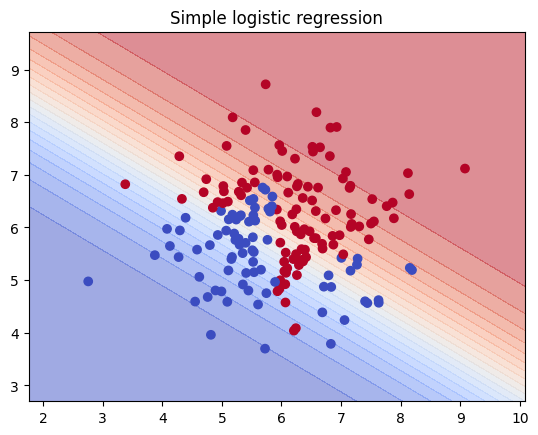

In [32]:
# Use DecisionBoundaryDisplay to display a heatmap corresponding to the estimated probabilities
disp = DecisionBoundaryDisplay.from_estimator(
    logreg, X_train,
    response_method="predict_proba",
    cmap=plt.cm.coolwarm, # colors to use (0 is blue, 1 is red)
    alpha=0.5, # level of transparency
    levels=20 # use 20 different nuances of color
)
# Add the training points on top using a scatterplot
disp.ax_.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=plt.cm.coolwarm)
plt.title("Simple logistic regression")
plt.show()

**Does this look like a good fit?**

Not at all  deosn't split the blue and the red very well. It is not really able to split well since the boundary between the two look non-linear.

**Could we adapt our logistic regression model to have non-linear decision boundaries? How?**

We could either do like last time where we adapt the features to be non linear then fit a linear model on it OR we could use a non linear classifier such as SVM or random forest but if we wanted to keep linear regression we could change the kernel like rbf/poly (which I remember of the top of my head but I don't remember exactly how they work).

## Non-linear logistic regression

**Train a logistic regression model using polynomial features. Are there any hyper-parameter? If yes, use a <ins>rigorous</ins> selection process to select an appropriate value.**

You can ignore regularization for now.

In [48]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression

# i think the polynomial number is a hyperparameter so lets measure it ?? not sure if this is what is wanted

best_degree = 1

best_val_score = 0.0

for degree in range(1,20):
    # this is the poly thing
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train)
    X_val_poly = poly.transform(X_val) # bbkk

    # train unregulated log reg
    model = LogisticRegression(penalty=None, max_iter=10000)
    model.fit(X_train_poly, y_train)

    # evaluation 
    val_score = model.score(X_val_poly, y_val)
    print(f"Degree {degree}: Validation Accuracy = {val_score}")


if val_score > best_val_score:
        best_val_score = val_score
        best_degree = degree

print(f"\nBest Polynomial Degree: {best_degree}")
print(f"Best Validation Score: {best_val_score}")
"""
Best Polynomial Degree: 19
Best Validation Score: 0.95
"""

Degree 1: Validation Accuracy = 0.8333333333333334
Degree 2: Validation Accuracy = 0.8333333333333334
Degree 3: Validation Accuracy = 0.8833333333333333


/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Volumes

Degree 4: Validation Accuracy = 0.95


/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret =

Degree 5: Validation Accuracy = 0.9333333333333333


/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret =

... (22 outputs left out)

Degree 17: Validation Accuracy = 0.95


/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret =

Degree 18: Validation Accuracy = 0.95
Degree 19: Validation Accuracy = 0.95

Best Polynomial Degree: 19
Best Validation Score: 0.95


/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret =

**If you were to proudly announce the performance of your model to the public, what is the value that you would you disclose?**

In [56]:
poly = PolynomialFeatures(degree=degree)
X_train_best = poly.fit_transform(X_train)
X_test_best = poly.fit_transform(X_test)
final_model = LogisticRegression(penalty=None, max_iter=10000) # put max iter but still complaining ; probably because no regurlization
final_model.fit(X_train_best, y_train)
test_score = final_model.score(X_test_best, y_test)

print(f"Disclosed Performance (Test Accuracy): {test_score}")
#Disclosed Performance (Test Accuracy): 0.95

/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X

Disclosed Performance (Test Accuracy): 0.95


/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret =

Now, we may want to also visualize the decision boundaries of our model with polynomial features.

Unfortunately, giving a matrix X_train_poly (for instance) of shape (100, 10) (for instance) to DecisionBoundaryDisplay.from_estimator will result in an error, as DecisionBoundaryDisplay only knows how to handle pixels in 2D, not in 10D.

Fortunately, we can combine a series of transformation on X_train as a single estimator using scikit-learn's Pipeline. We can also introduce other preprocessing (or even postprocessing) steps in the process, such as feature standardization.

In [57]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler

In [58]:
# Create a pipeline that first standardizes the data,
# then transforms it with PolynomialFeatures
# and finally fits LogisticRegression
pipeline = Pipeline([
    ('scaler', StandardScaler()), # standardize features
    ('poly', PolynomialFeatures(degree=2)), # for instance
    ('logreg', LogisticRegression(max_iter=500)) # for instance
])

Now we can directly call "fit" on this pipeline to train the model, and give this pipeline to DecisionBoundaryDisplay so that for each pixel, it can:
- compute the corresponding polynomial features from the initial 2D coordinates
- give these features to our logistic regression

and then display the heatmap of estimated probabilities as previously.

In [59]:
# Fit the pipeline
pipeline.fit(X_train, y_train)

/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept


Pipeline(steps=[('scaler', StandardScaler()), ('poly', PolynomialFeatures()),
                ('logreg', LogisticRegression(max_iter=500))])

/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


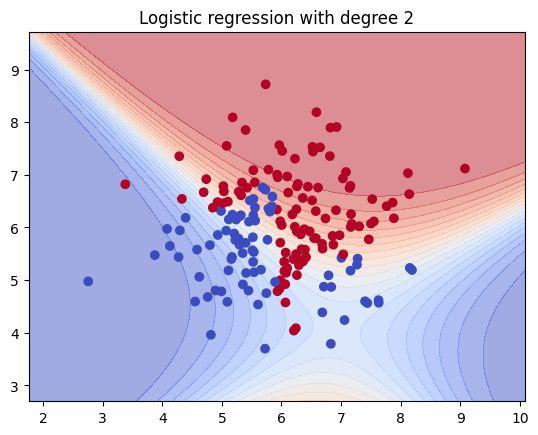

In [60]:
# Give the pipeline to DecisionBoundaryDisplay to plot the probability heatmap
disp = DecisionBoundaryDisplay.from_estimator(
    pipeline, X_train,
    response_method="predict_proba",
    cmap=plt.cm.coolwarm, # colors to use (0 is blue, 1 is red)
    alpha=0.5, # level of transparency
    levels=20 # use 20 different nuances of color
)
disp.ax_.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=plt.cm.coolwarm)
plt.title("Logistic regression with degree 2")
plt.show()

**Do the features <ins>used</ins> by the model have zero mean and unit standard deviation with our current pipeline? If not, what should be changed so that this is the case?**

In [61]:
# well because they standard scalar before polynomial featuresthis reduces the range of values dramatically and kind of warps the distribution.
pipeline = Pipeline([
    ('poly', PolynomialFeatures(degree=best_degree)), #put the best one in thre i think its 5
    ('scaler', StandardScaler()), # standardize features
    ('logreg', LogisticRegression(max_iter=500)) # for instance
])

**Now plot the probability heatmap of *your* model from earlier**

/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Volumes/CrucialX6/Home/neuro-venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features] = X

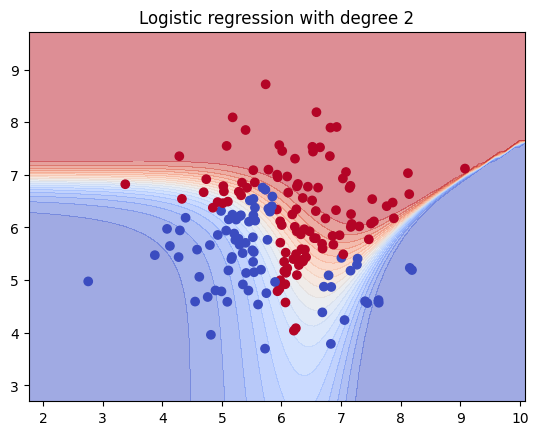

In [62]:
pipeline.fit(X_train, y_train)

disp = DecisionBoundaryDisplay.from_estimator(
    pipeline, X_train,
    response_method="predict_proba",
    cmap=plt.cm.coolwarm, # colors to use (0 is blue, 1 is red)
    alpha=0.5, # level of transparency
    levels=20 # use 20 different nuances of color
)
disp.ax_.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=plt.cm.coolwarm)
plt.title("Logistic regression with degree 2")
plt.show()

**Any observation?**

I observe that the data is much better speard out than when standard scalar then polynomial. This better seperation of the two classes helps the classifier better classify points from the two classes.

# Exploration of other algorithms

Now, we will use the heatmap displays to build some intuition about what happens with other classification algorithms.

## K-Nearest Neighbors

**Can we obtain probabilities with K-NN?**

For this question, "probability" may be interpreted as "a measure of confidence more precise than a yes/no answer".

In [64]:
# well not exactly put you can make a math equation to make an estimate of the probability by looking at neighbor class and distance such that you can use both for a confidence/probability.

**Fit K-NN on the training dataset with K ranging for 1 to 6, and plot the confidence heatmap.**

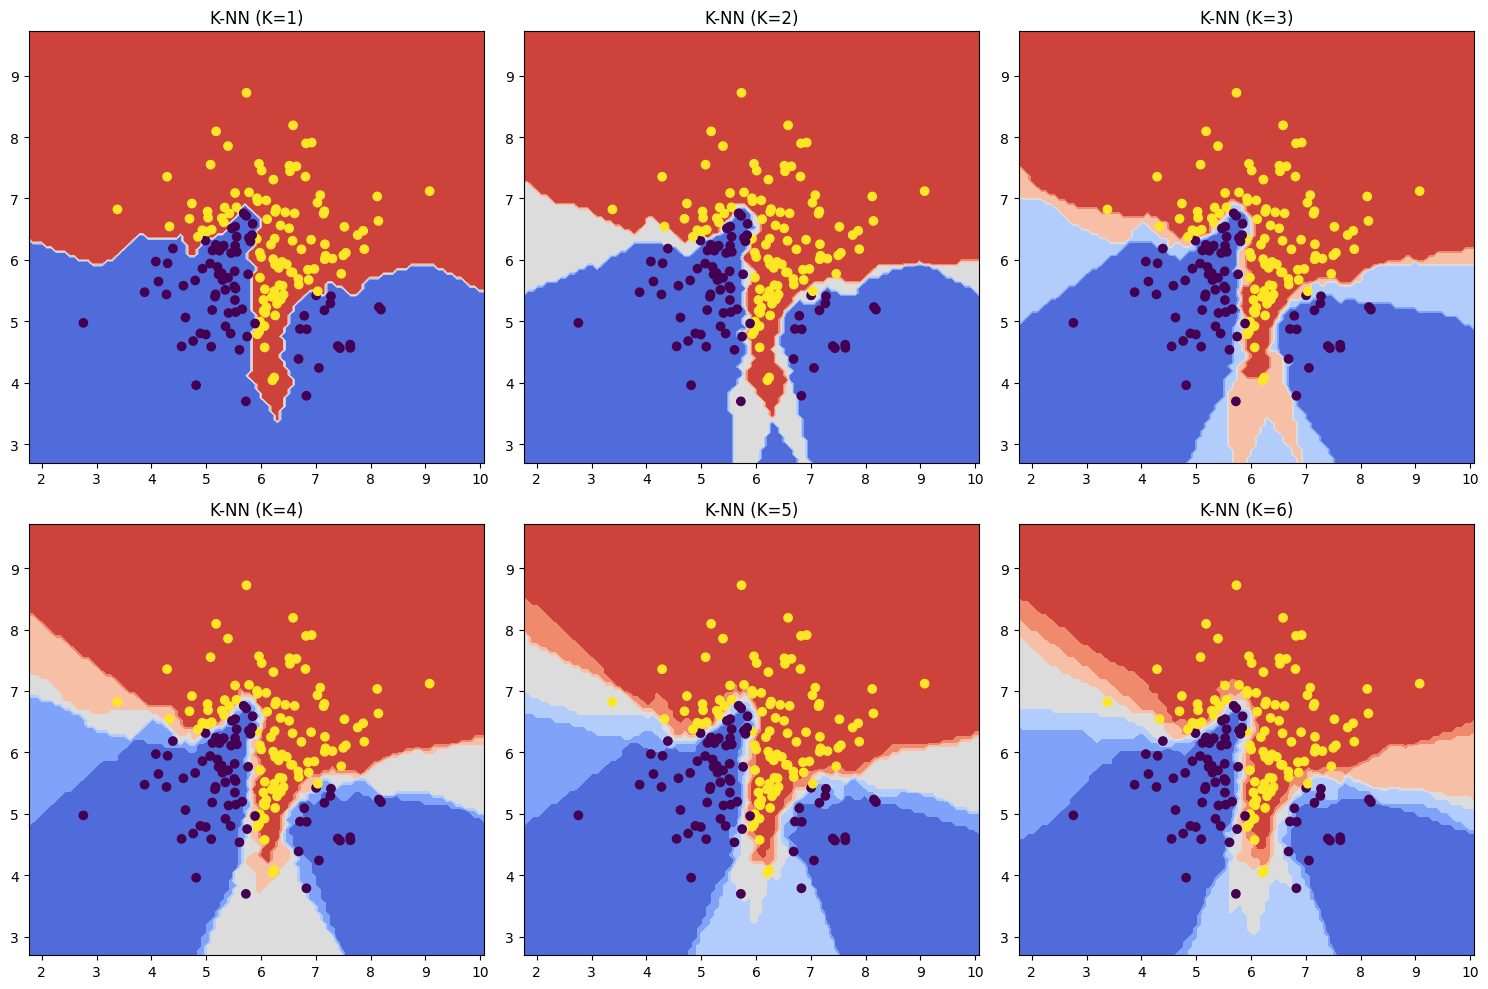

In [79]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for k, ax in zip(range(1, 7), axes.ravel()):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    
    disp = DecisionBoundaryDisplay.from_estimator( # a super super cool package. I've been using sklearn for a while but I didn't know they had this
        knn,
        X_train,
        response_method="predict_proba",
        cmap=plt.cm.coolwarm,
        ax=ax
    )
    disp.ax_.scatter(X_train[:, 0], X_train[:, 1], c=y_train)
    ax.set_title(f"K-NN (K={k})")

plt.tight_layout()
plt.show()

**Briefly explain what's happening**

We see what the model will predict and with what confidence depending on how red or blue that point is on the graph. we also see the individual points in yellow and purplel. we are also looking at how the decision boundaries are changing as the ammount of neighbors chage for knn.

## Naive Bayes

**Choose a suitable Naive Bayes classifier, and do same thing**

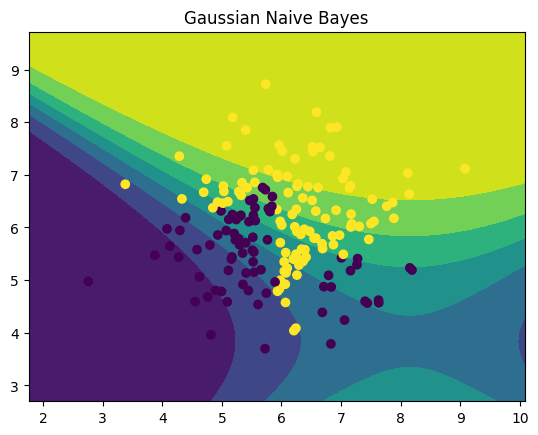

In [81]:
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

disp = DecisionBoundaryDisplay.from_estimator(
    gnb,
    X_train,
    response_method="predict_proba",
)

disp.ax_.scatter(X_train[:, 0], X_train[:, 1], c=y_train)
plt.title("Gaussian Naive Bayes")
plt.show()

**Are there any hyper-parameter?**

Well yes if you include the possibility for data manipulation and the fact that you can change various part of the guassianNB but we didn't test or change any of the default ones. So yes but we didn't manipulate them directly (we didn't tune a prior).

***Bonus question: explain what is going on your plot.***